In [1]:
#Tous les imports nécessaires
import mesa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

c:\Users\essoa\OneDrive\Desktop\School staff\Tp2_Agentic\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
#Définition de l'agent
class CitizenAgent(mesa.Agent):
    """Un individu ayant une opinion qui évolue selon ses voisins."""
    def __init__(self, model, alpha):
        # Enregistrement automatique dans Mesa 3
        super().__init__(model)
        
        # Opinion initiale tirée aléatoirement dans [0, 1]
        self.opinion = self.model.random.random()
        # Niveau d'influence sociale
        self.alpha = alpha

    def step(self):
        # Récupération des 8 voisins de Moore (sans s'inclure soi-même)
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)
        
        if len(neighbors) > 0:
            # Calcul de l'opinion moyenne des voisins
            mean_opinion = np.mean([neighbor.opinion for neighbor in neighbors])
            
            # Mise à jour de l'opinion selon la formule du TP
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)

In [4]:
#Implémentation du modèle
class OpinionModel(mesa.Model):
    """Modèle simulant la formation de l'opinion publique sur une grille."""
    def __init__(self, width, height, alpha=0.2, seed=None):
        super().__init__(seed=seed)
        
        # Grille toroïdale (bords communicants)
        self.grid = mesa.space.MultiGrid(width, height, torus=True)
        self.alpha = alpha
        
        # Initialisation : un agent par case
        for _, (x, y) in self.grid.coord_iter():
            agent = CitizenAgent(self, self.alpha)
            self.grid.place_agent(agent, (x, y))
            
        # Collecteur de données
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean([a.opinion for a in m.agents]),
                "Variance (Dispersion)": lambda m: np.var([a.opinion for a in m.agents])
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

    def step(self):
        # 1. Collecte de l'état actuel
        self.datacollector.collect(self)
        # 2. Activation aléatoire des agents (syntaxe Mesa 3)
        self.agents.shuffle_do("step")

c:\Users\essoa\OneDrive\Desktop\School staff\Tp2_Agentic\.venv\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


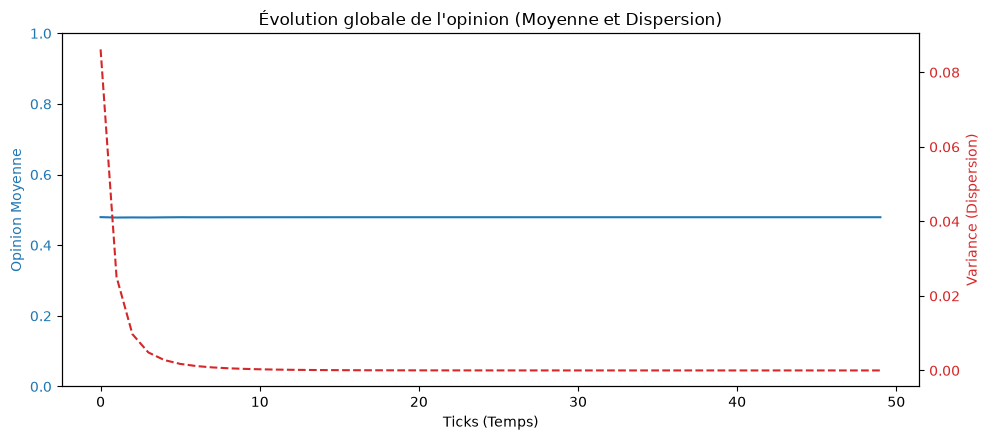

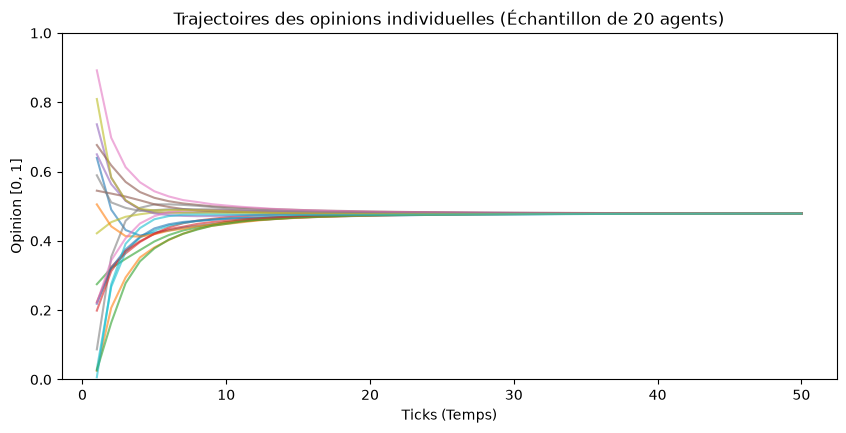

In [5]:
#Simulation et tracé des graphiques
# 1. Paramètres
WIDTH = 10
HEIGHT = 10
ALPHA = 0.5
STEPS = 50

# 2. Instanciation et exécution
model = OpinionModel(width=WIDTH, height=HEIGHT, alpha=ALPHA, seed=42)

for i in range(STEPS):
    model.step()

# 3. Récupération des données
model_data = model.datacollector.get_model_vars_dataframe()
agent_data = model.datacollector.get_agent_vars_dataframe()

# 4. Graphique global : Moyenne et Variance
fig, ax1 = plt.subplots(figsize=(10, 4.5))

color = 'tab:blue'
ax1.set_xlabel('Ticks (Temps)')
ax1.set_ylabel('Opinion Moyenne', color=color)
ax1.plot(model_data.index, model_data['Opinion Moyenne'], color=color, label="Moyenne")
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Variance (Dispersion)', color=color)
ax2.plot(model_data.index, model_data['Variance (Dispersion)'], color=color, linestyle='--', label="Variance")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Évolution globale de l'opinion (Moyenne et Dispersion)")
fig.tight_layout()
plt.show()

# 5. Graphique individuel : Trajectoires d'un échantillon de 20 agents
agent_opinions = agent_data.unstack(level=1)['Opinion']
sample_agents = agent_opinions.columns[:20]

plt.figure(figsize=(10, 4.5))
for agent_id in sample_agents:
    plt.plot(agent_opinions.index, agent_opinions[agent_id], alpha=0.6)

plt.title("Trajectoires des opinions individuelles (Échantillon de 20 agents)")
plt.xlabel("Ticks (Temps)")
plt.ylabel("Opinion [0, 1]")
plt.ylim(0, 1)
plt.show()

## Réponses aux Questions d'Analyse

### Compréhension théorique
1. **Impact de $\alpha$ :** 
   - Le paramètre $\alpha$ contrôle la vitesse d'assimilation sociale.
   - Si $\alpha \to 0$, l'inertie est maximale : les agents ne modifient presque pas leur avis et la variance reste élevée très longtemps.
   - Si $\alpha = 1$, la convergence est quasi instantanée : chaque agent adopte immédiatement la moyenne exacte de ses voisins, faisant chuter la variance à 0 en quelques ticks seulement.

2. **Absence de polarisation / formation de groupes :**
   - La règle de mise à jour calcule une moyenne arithmétique globale sur tous les voisins de Moore sans seuil de tolérance (pas de filtrage des avis contradictoires).
   - Sur une grille toroïdale fortement connexe, cela correspond à un processus markovien ergodique (modèle de diffusion de DeGroot) : l'enveloppe des opinions se contracte obligatoirement jusqu'à un consensus parfait ($\sigma^2 \to 0$).

3. **Émergence (Protocole ODD) :**
   - L'émergence se traduit par la formation d'un état macroscopique ordonné (un consensus unanime) à partir de simples règles microscopiques locales (la moyenne de 8 voisins). Aucun agent ne cherche activement le consensus global.

---

### Technique et manipulation de Mesa 3
1. **`shuffle_do("step")` vs listes :**
   - Cette syntaxe applique la méthode sur l'ensemble d'agents (`AgentSet`) dans un ordre aléatoire renouvelé à chaque tick.
   - Cela supprime les biais d'ordre séquentiels où les premiers éléments d'une liste statique influenceraient toujours les suivants avant que ces derniers ne s'exécutent.

2. **`model_reporters` vs `agent_reporters` :**
   - `model_reporters` agrège les métriques globales du système (ex. variance, moyenne) pour suivre la dynamique macroscopique.
   - `agent_reporters` capture l'état individuel de chaque agent à chaque tick (index multi-niveau), indispensable pour tracer les trajectoires individuelles et vérifier la dispersion réelle.

3. **Effet de `torus=True` :**
   - La topologie en tore connecte les bords opposés (`x=0` avec `x=width-1` et `y=0` avec `y=height-1`).
   - Cela assure que chaque cellule possède exactement 8 voisins sans effets de frontière.

---

### Ouverture et esprit critique
1. **Biais de confirmation (Modèle de Deffuant-Weisbuch) :**
   - Modification :
     ```python
     close_neighbors = [n for n in neighbors if abs(n.opinion - self.opinion) < epsilon]
     if close_neighbors:
         mean_opinion = np.mean([n.opinion for n in close_neighbors])
         self.opinion += self.alpha * (mean_opinion - self.opinion)
     ```
   - *Phénomène émergent :* Au lieu d'un consensus global, la population se segmente en plusieurs clusters d'opinion distincts (polarisation ou chambres d'écho).

2. **Réseau social :**
   - On remplacerait `MultiGrid` par un `NetworkGrid` adossé à un graphe NetworkX sans échelle (scale-free / Barabási-Albert) pour modéliser des nœuds à très haut degré (hubs / influenceurs).